•	Läs in datan: Spara i en struktur så man vet värden som hör till Pichu respektive Pikachu.

In [33]:
#skapa funktion för att läsa in filerna 

def las_in_pokemon(filnamn):
    temp_lista = []  
    
    with open(filnamn, "r") as fil:
        for rad in fil:
            rad = rad.strip()
            
            if "width" in rad:
                continue
                
            if rad:
                steg_1 = rad.replace("(", "").replace(")", "")
                delar = steg_1.split(",")
                
                bredd = float(delar[0])
                höjd = float(delar[1])
                
                temp_lista.append([bredd, höjd])
                
    return temp_lista  



# läs in båda filerna
pichu_lista = las_in_pokemon("data/pichu.txt")
pikachu_lista = las_in_pokemon("data/pikachu.txt")



Skapa listor för x och y för alla punkter

In [34]:
# Skapa tomma listor för x och y för Pichu
pichu_x = []
pichu_y = []

for p in pichu_lista:
    pichu_x.append(p[0]) 
    pichu_y.append(p[1]) 



# Skapa tomma listor för x och y för pikachu
pikachu_x = []
pikachu_y = []

for p in pikachu_lista:
    pikachu_x.append(p[0]) 
    pikachu_y.append(p[1]) 




# testpunkter 
testpunkter_lista = [[25, 35], [15,14], [26,30], [22,45]]


# Skapa tomma listor för x och y för testpunkter
testpunkt_x = []
testpunkt_y = []

# Loopa igenom 
for p in testpunkter_lista:
    testpunkt_x.append(p[0]) # index 0 är bredd (X)
    testpunkt_y.append(p[1]) # index 1 är höjd (Y)





Plotta punkter i ett koordinatsystem. Ge Pichu-punkterna blå färg och Pikachu  röd färg.

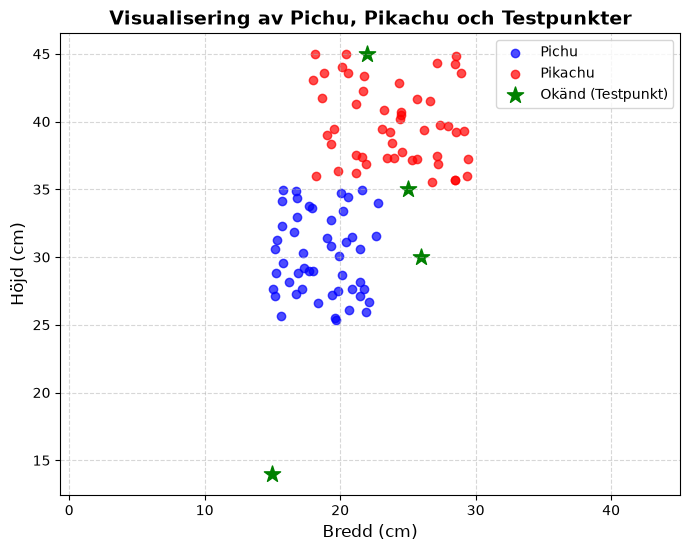

In [ ]:
import matplotlib.pyplot as plt

# Skapa själva fönstret
plt.figure(figsize=(8, 6))

# Pichu som BLÅ punkter 
plt.scatter(pichu_x, pichu_y, color="blue", label="Pichu", alpha=0.7)

# Pikachu som RÖDA punkter 
plt.scatter(pikachu_x, pikachu_y, color="red", label="Pikachu", alpha=0.7)

# testpunkter som gröna stjärnor 
plt.scatter(testpunkt_x, testpunkt_y, color="green", marker="*", s=150, label="Okänd (Testpunkt)")



# rubriker på axlarna och diagrammet
plt.xlabel("Bredd (cm)", fontsize=12)
plt.ylabel("Höjd (cm)", fontsize=12)
plt.title("Visualisering av Pichu, Pikachu och Testpunkter", fontsize=14, fontweight="bold")

# färgförklaring
plt.legend()

# rutnät så det blir lättare att läsa av koordinater
plt.grid(True, linestyle="--", alpha=0.5)

#plt.axis('equal')

# Visa diagrammet på skärmen!
plt.show()

Beräkna avstånd från respektive testpunkt

In [36]:
import math


# funktion för beräkna avstånd mellan två punkter
def avstånd(x1,y1,x2,y2):
    
    

    avstånd_beräkning = math.sqrt((x2-x1)**2 + (y2-y1)**2)

    return avstånd_beräkning 



# funktion för beräkna avstånd mellan testpunkt och punkt från lista
def hämta_kortaste_avstånd(en_testpunkt, pokemon_lista):
    resultat_lista = []
    
    # Vi loopar igenom listan 
    for i in range(len(pokemon_lista)):
        # Vi använder parametrarna istället för hårdkodade namn!
        resultat_lista.append(avstånd(*en_testpunkt, *pokemon_lista[i]))
        
    # Hitta det minsta talet
    minsta_avståndet = min(resultat_lista)
    
   
    return minsta_avståndet


# Nedan kommer beräkningarna 


for k in range(4):

    test_punkt = testpunkter_lista[k]

    # funktionen för Pichu
    avstånd_pichu = hämta_kortaste_avstånd(test_punkt, pichu_lista)

    # funktion för Pikachu
    avstånd_pikachu = hämta_kortaste_avstånd(test_punkt, pikachu_lista)


    # if-sats för att gissa
    if avstånd_pichu < avstånd_pikachu:
        print(f"Kortaste avståndet ({round(avstånd_pichu,2)} cm) är till en Pichu.  Testpunkten {test_punkt} bedöms därför vara en Pichu")
    else:
        print(f"Kortaste avståndet ({round(avstånd_pikachu,2)} cm) är till en Pikachu.  Testpunkten {test_punkt} bedöms därför vara en Pikachu")





Kortaste avståndet (1.83 cm) är till en Pikachu.  Testpunkten [25, 35] bedöms därför vara en Pikachu
Kortaste avståndet (11.65 cm) är till en Pichu.  Testpunkten [15, 14] bedöms därför vara en Pichu
Kortaste avståndet (3.69 cm) är till en Pichu.  Testpunkten [26, 30] bedöms därför vara en Pichu
Kortaste avståndet (1.59 cm) är till en Pikachu.  Testpunkten [22, 45] bedöms därför vara en Pikachu


Användarinput: Låt en användare skriva in valfri bredd och höjd i terminalen. Bygg in felhantering  så att programmet inte kraschar om användaren råkar skriva in bokstäver eller negativa tal.

In [29]:
while True:
    try:
        input_bredd = float(input('Ange en bredd i cm: '))

        if input_bredd <= 0:
            print('Fel: du måste ange ett positivt tal. Försök igen.')
            continue  # Startar om loopen direkt om talet är för litet

        # Om vi skrivit in rätt siffror bryts loopen
        break 

    except ValueError:
        print('Fel: du måste skriva ett tal med siffror. Försök igen.')
        continue  # Startar om loopen direkt om användaren skrev bokstäver


while True:
    try:
        input_höjd = float(input('Ange en höjd i cm: '))

        if input_höjd <= 0:
            print('Fel: du måste ange ett positivt tal. Försök igen.')
            continue  # Startar om loopen direkt om talet är för litet

        # Om vi skrivit in rätt siffror bryts loopen
        break 

    except ValueError:
        print('Fel: du måste skriva ett tal med siffror. Försök igen.')
        continue  # Startar om loopen direkt om användaren skrev bokstäver


användar_punkt = [input_bredd,input_höjd] # Skapa lista för användarpunkt

# Skapa tomma listor för x y användarpunkt
användar_punkt_x = []
användar_punkt_y = []

användar_punkt_x = användar_punkt[0]
användar_punkt_y = användar_punkt[1]

print(användar_punkt_x)
print(användar_punkt_y)


18.0
36.0


Visualisering: Plotta användarpunkten i ett koordinatsystem. Pichu-punkterna blå färg och Pikachu  röd färg.

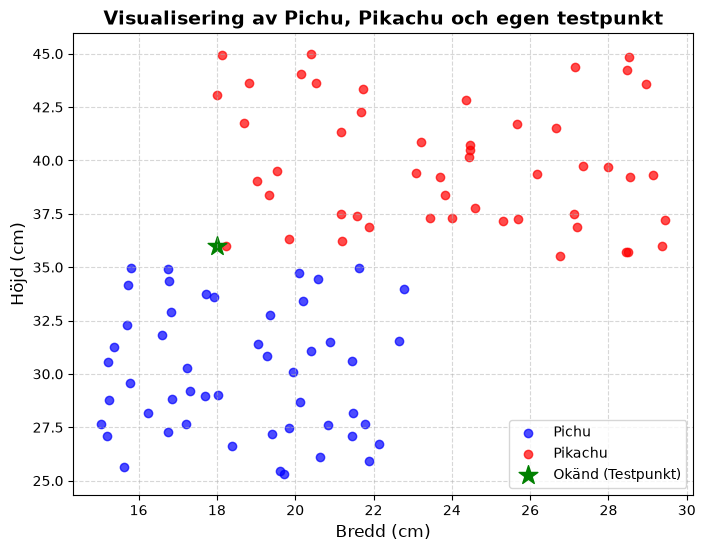

In [30]:
# skapa tomma listor för x och y för Pichu
pichu_x = []
pichu_y = []

for p in pichu_lista:
    pichu_x.append(p[0]) # index 0 är bredd (X)
    pichu_y.append(p[1]) # index 1 är höjd (Y)



# Skapa tomma listor för x och y för pikachu
pikachu_x = []
pikachu_y = []

for p in pikachu_lista:
    pikachu_x.append(p[0]) # index 0 är bredd (X)
    pikachu_y.append(p[1]) # index 1 är höjd (Y)




# plott inklusive användarpunkt
import matplotlib.pyplot as plt

# Skapa själva fönstret
plt.figure(figsize=(8, 6))

# Pichu som BLÅ punkter 
plt.scatter(pichu_x, pichu_y, color="blue", label="Pichu", alpha=0.7)

# Pikachu som RÖDA punkter 
plt.scatter(pikachu_x, pikachu_y, color="red", label="Pikachu", alpha=0.7)

# testpunkter som gröna stjärnor 
plt.scatter(användar_punkt_x, användar_punkt_y, color="green", marker="*", s=200, label="Okänd (Testpunkt)")



# rubriker på axlarna och diagrammet
plt.xlabel("Bredd (cm)", fontsize=12)
plt.ylabel("Höjd (cm)", fontsize=12)
plt.title("Visualisering av Pichu, Pikachu och egen testpunkt", fontsize=14, fontweight="bold")

# färgförklaring
plt.legend()

# rutnät så det blir lättare att läsa av koordinater
plt.grid(True, linestyle="--", alpha=0.5)

# Visa diagrammet på skärmen!
plt.show()


De 5 närmaste (Majoritetsröstning): Istället för att bara titta på en närmaste punkt, ska man nu leta upp de 5 närmaste punkterna. Om till exempel 3 av dem är Pikachus och 2 är Pichus, vinner Pikachu eftersom det är i majoritet.

In [31]:
import math

# avståndsfunktion
def avstånd(x1, y1, x2, y2):
    avstånd_beräkning = math.sqrt((x2-x1)**2 + (y2-y1)**2)
    return avstånd_beräkning 

# Funktion för att hämta de 5 kortaste avstånden
def fem_kortaste_avstånd(en_testpunkt, pokemon_lista):
    resultat_lista = []
    for i in range(len(pokemon_lista)):
        resultat_lista.append(avstånd(*en_testpunkt, *pokemon_lista[i]))

    resultat_lista_sorterad = sorted(resultat_lista)
    fem_minsta = resultat_lista_sorterad[:5]
    return fem_minsta

#Beräkningar startar
#användar_punkt = [25, 35]

avstånd_pichu = fem_kortaste_avstånd(användar_punkt, pichu_lista)
avstånd_pikachu = fem_kortaste_avstånd(användar_punkt, pikachu_lista)

minsta_av_pichu = []
minsta_av_pikachu = []

# VARV 1 
if avstånd_pikachu[0] < avstånd_pichu[0]:
    minsta_av_pikachu.append(avstånd_pikachu[0])
    del avstånd_pikachu[0]
else: 
    minsta_av_pichu.append(avstånd_pichu[0])
    del avstånd_pichu[0]  

# VARV 2 
if avstånd_pikachu[0] < avstånd_pichu[0]:
    minsta_av_pikachu.append(avstånd_pikachu[0])
    del avstånd_pikachu[0]
else: 
    minsta_av_pichu.append(avstånd_pichu[0])
    del avstånd_pichu[0] 

# VARV 3 
if avstånd_pikachu[0] < avstånd_pichu[0]:
    minsta_av_pikachu.append(avstånd_pikachu[0])
    del avstånd_pikachu[0]
else: 
    minsta_av_pichu.append(avstånd_pichu[0])
    del avstånd_pichu[0]  

# VARV 4 
if avstånd_pikachu[0] < avstånd_pichu[0]:
    
    minsta_av_pikachu.append(avstånd_pikachu[0])
    del avstånd_pikachu[0]
else: 
    minsta_av_pichu.append(avstånd_pichu[0])
    del avstånd_pichu[0]  

# VARV 5
if avstånd_pikachu[0] < avstånd_pichu[0]:
    minsta_av_pikachu.append(avstånd_pikachu[0])
    del avstånd_pikachu[0]
else: 
    minsta_av_pichu.append(avstånd_pichu[0])
    del avstånd_pichu[0]  


#Slutsats
if len(minsta_av_pikachu) > len(minsta_av_pichu):
    print('Testpunkten är enligt majoritet en Pikachu!')
else:
    print('Testpunkten är enligt majoritet en Pichu!')


print("Närmaste Pikachu-grannar:", minsta_av_pikachu)
print("Närmaste Pichu-grannar:", minsta_av_pichu)


Testpunkten är enligt majoritet en Pichu!
Närmaste Pikachu-grannar: [0.23572749788818886, 1.862316516158377]
Närmaste Pichu-grannar: [1.6689069214793413, 2.0353700136315114, 2.253536232566899]


In [32]:
import math

# avståndsfunktion
def avstånd(x1, y1, x2, y2):
    avstånd_beräkning = math.sqrt((x2-x1)**2 + (y2-y1)**2)
    return avstånd_beräkning 

# Funktion för att hämta de 5 kortaste avstånden
def fem_kortaste_avstånd(en_testpunkt, pokemon_lista):
    resultat_lista = []
    for i in range(len(pokemon_lista)):
        resultat_lista.append(avstånd(*en_testpunkt, *pokemon_lista[i]))

    resultat_lista_sorterad = sorted(resultat_lista)
    fem_minsta = resultat_lista_sorterad[:5]
    return fem_minsta

#Beräkningar startar
#användar_punkt = [25, 35]

avstånd_pichu = fem_kortaste_avstånd(användar_punkt, pichu_lista)
avstånd_pikachu = fem_kortaste_avstånd(användar_punkt, pikachu_lista)

minsta_av_pichu = []
minsta_av_pikachu = []

for p in range(5):


    if avstånd_pikachu[0] < avstånd_pichu[0]:
        minsta_av_pikachu.append(avstånd_pikachu[0])
        del avstånd_pikachu[0]
    else: 
        minsta_av_pichu.append(avstånd_pichu[0])
        del avstånd_pichu[0]  




#Slutsats
if len(minsta_av_pikachu) > len(minsta_av_pichu):
    print('Testpunkten är enligt majoritet en Pikachu!')
else:
    print('Testpunkten är enligt majoritet en Pichu!')


print("Närmaste Pikachu-grannar:", minsta_av_pikachu)
print("Närmaste Pichu-grannar:", minsta_av_pichu)


Testpunkten är enligt majoritet en Pichu!
Närmaste Pikachu-grannar: [0.23572749788818886, 1.862316516158377]
Närmaste Pichu-grannar: [1.6689069214793413, 2.0353700136315114, 2.253536232566899]
